# Estimating Full-Load Electrical Output

**Machine Learning Zoomcamp 2026 · Midterm project**

An analyst estimates a combined-cycle power plant's net electrical output in MW
from four same-hour measurements: ambient temperature (`AT`), exhaust vacuum
(`V`), ambient pressure (`AP`), and relative humidity (`RH`). An API makes the
estimate available to a small scenario-exploration tool.

This is a regression benchmark for one plant operating at full load. The inputs
are same-hour observations; this project does **not** demonstrate forecasting
future hours, causal interventions, or generalization to another plant.

**Data:** UCI Combined Cycle Power Plant, DOI
[10.24432/C5002N](https://doi.org/10.24432/C5002N), Pinar Tufekci and Heysem Kaya,
CC BY 4.0. Measurements were collected in 2006–2011. The original workbook
contains five shuffled versions of the same observations. We use **Sheet1 only**.

**Question:** Can nonlinear models improve on a linear baseline while remaining
small enough to serve on a CPU?

Run all cells from the project directory after `uv sync --locked`.
This notebook uses the same reusable training implementation as `train.py`.
The training cell deliberately retrains and regenerates artifacts and reports.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
from pathlib import Path
import json
import platform
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from data import ROOT, FEATURES, TARGET, load_data, split_data
from train import candidates, run_experiment

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False, 'axes.spines.right': False})
REPORTS = ROOT / 'reports'
REPORTS.mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.11.15 | scikit-learn: 1.7.2


## 1. Data quality and leakage prevention

The included CSV is a lossless conversion of Sheet1. `data.py` can download the
original archive and regenerate it; source and CSV checksums are recorded in
`data/source_manifest.json`.

Exact duplicate rows are removed **before** the split. We also check that no
identical input vector appears in two partitions. Missing values are checked
honestly: this release has none. Each model nevertheless includes a training-fit
median imputer, making preprocessing explicit and fold-safe.

The source contains RH measurements slightly above 100%. These are retained and
documented rather than silently clipped. With no timestamps in the distributed
table, a temporal split cannot be reconstructed.

In [2]:
frame, quality = load_data()
print(json.dumps(quality, indent=2))
display(frame.head())
train, validation, test = split_data(frame)
print('Split sizes:', {name: len(part) for name, part in [('train', train), ('validation', validation), ('test', test)]})
display(train.describe().T)

{
  "source_rows": 9568,
  "clean_rows": 9527,
  "duplicates_removed": 41,
  "missing_values": {
    "AT": 0,
    "V": 0,
    "AP": 0,
    "RH": 0,
    "PE": 0
  },
  "csv_sha256": "51848da3c8b8c29f709f159fad95443eaa8ff2e95c721a00bba582048cd207e4"
}


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


Split sizes: {'train': 5715, 'validation': 1906, 'test': 1906}


,count,mean,std,min,25%,50%,75%,max
AT,5715.0,19.629542,7.464336,1.81,13.550,20.32,25.660,37.11
V,5715.0,54.241440,12.780729,25.36,41.580,52.08,66.540,81.56
AP,5715.0,1013.266357,5.998729,992.89,1009.095,1012.92,1017.295,1033.30
RH,5715.0,73.244397,14.582053,26.30,63.340,74.77,84.900,100.15
PE,5715.0,454.426313,17.081589,420.26,439.830,451.67,468.455,495.76


## 2. Exploratory data analysis — training partition only

Inspect target spread and feature coverage, then investigate associations.
Temperature is expected to be associated with output, but a correlation cannot
establish that independently changing one variable will change plant output.

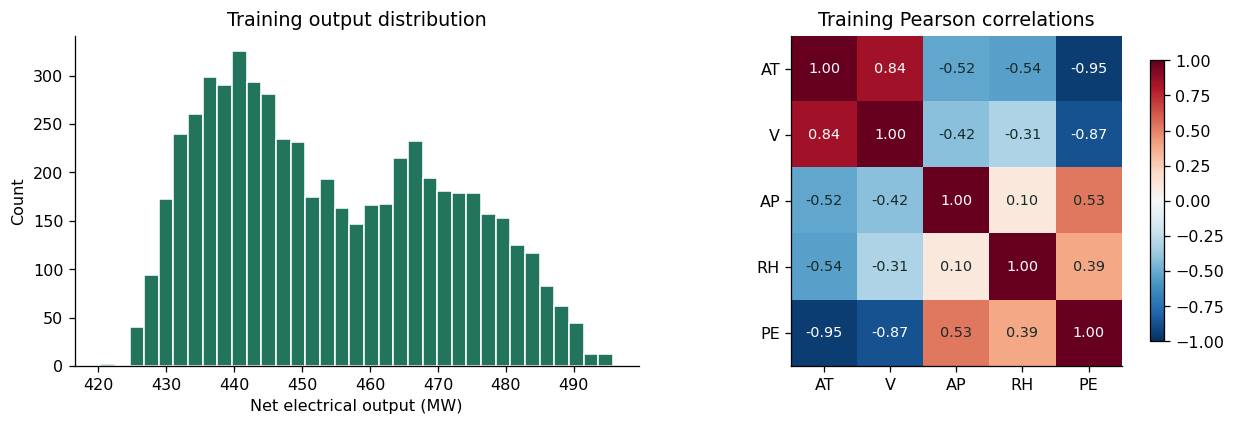

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(train[TARGET], bins=35, color='#23745c', edgecolor='white')
axes[0].set(title='Training output distribution', xlabel='Net electrical output (MW)', ylabel='Count')
correlations = train[FEATURES + [TARGET]].corr()
image = axes[1].imshow(correlations, cmap='RdBu_r', vmin=-1, vmax=1)
names = FEATURES + [TARGET]
axes[1].set_xticks(range(5), labels=names)
axes[1].set_yticks(range(5), labels=names)
axes[1].set_title('Training Pearson correlations')
for i in range(5):
    for j in range(5):
        axes[1].text(j, i, f'{correlations.iloc[i,j]:.2f}', ha='center', va='center',
                     color='white' if abs(correlations.iloc[i,j]) > .6 else '#172b29', fontsize=9)
fig.colorbar(image, ax=axes[1], shrink=.85)
fig.tight_layout()
fig.savefig(REPORTS / 'eda_target_correlations.png', dpi=150)
plt.show()

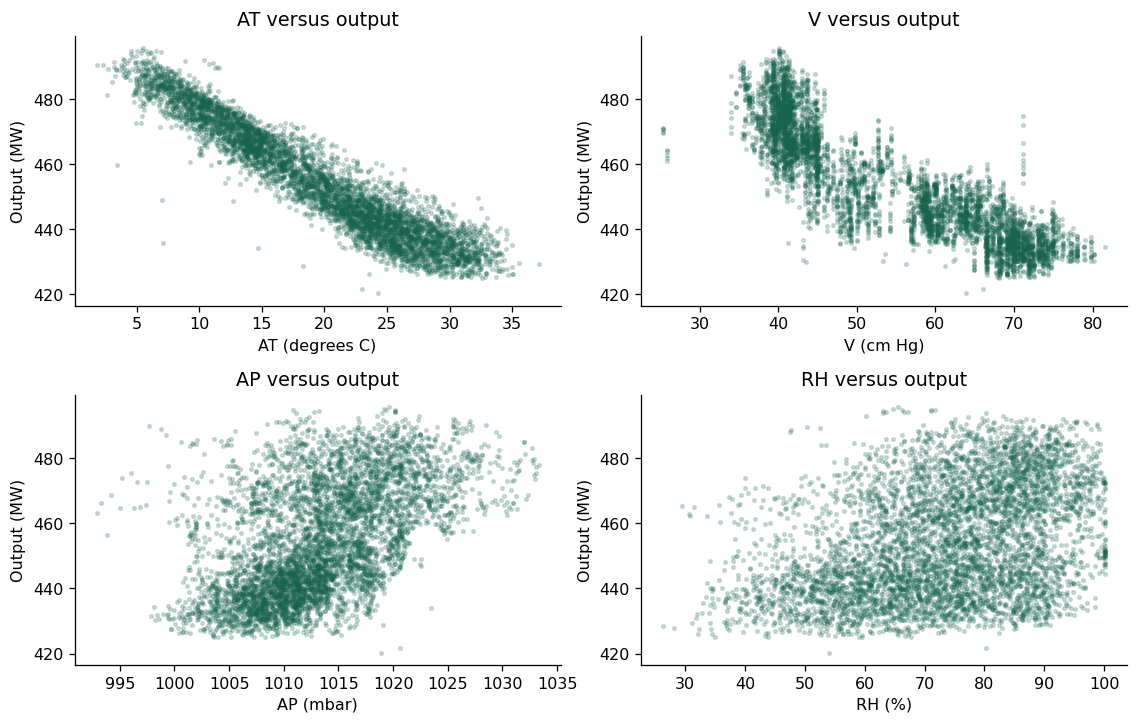

,correlation_with_output
AT,-0.947696
V,-0.868811
RH,0.387262
AP,0.526991


In [4]:
units = {'AT': 'degrees C', 'V': 'cm Hg', 'AP': 'mbar', 'RH': '%'}
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4))
for ax, feature in zip(axes.flat, FEATURES):
    ax.scatter(train[feature], train[TARGET], s=5, alpha=.20, color='#17644d', rasterized=True)
    ax.set(xlabel=f'{feature} ({units[feature]})', ylabel='Output (MW)', title=f'{feature} versus output')
fig.tight_layout()
fig.savefig(REPORTS / 'eda_feature_relationships.png', dpi=150)
plt.show()
display(correlations[TARGET].drop(TARGET).sort_values().to_frame('correlation_with_output'))

**EDA interpretation.** Output and temperature show a strong negative
association. Vacuum is also associated with output and with temperature, so
their predictive contributions may overlap. Pressure and humidity can add
information even if their marginal correlations are smaller. These patterns
motivate comparing linear, polynomial, bagged-tree, and boosted-tree models.

No observations are discarded solely because their target value is unusual.
The public dataset is already structured; cleaning here focuses on provenance,
duplicate handling, ranges, and a leakage-free evaluation design.

## 3. Training and parameter tuning

Primary metric: RMSE in MW, $\sqrt{\mathrm{mean}((y-\hat y)^2)}$.
MAE and R-squared provide additional context.

Training/validation/test proportions are approximately 60/20/20, seed 42.
Every hyperparameter search uses **three-fold CV on training data only**.
After tuning each family, choose the lowest validation RMSE. Then refit that
configuration on train + validation and evaluate it once on test. The test score
does not choose a model or tune a parameter.

In [5]:
specifications = []
for name, (pipeline, grid) in candidates().items():
    specifications.append({'model': name, 'tuned_parameters': grid or 'none (baseline)'})
display(pd.DataFrame(specifications))

,model,tuned_parameters
0,mean_baseline,none (baseline)
1,linear_regression,none (baseline)
2,polynomial_ridge,"{'model__alpha': [0.01, 0.1, 1.0, 10.0]}"
3,random_forest,"{'model__max_depth': [12, None], 'model__min_s..."
4,hist_gradient_boosting,"{'model__learning_rate': [0.05, 0.1], 'model__..."


In [6]:
# This is the same entry point called by `python train.py`.
# It trains models, saves models/model.joblib, and writes reports/metrics.json.
results = run_experiment()

Training mean_baseline...
  CV RMSE 17.0787; validation RMSE 16.8062
Training linear_regression...
  CV RMSE 4.5755; validation RMSE 4.5085
Training polynomial_ridge...
  CV RMSE 4.2512; validation RMSE 4.2453
Training random_forest...
  CV RMSE 3.5687; validation RMSE 3.4676
Training hist_gradient_boosting...
  CV RMSE 3.3565; validation RMSE 3.2335
Selected: hist_gradient_boosting Test: {'rmse_mw': 3.262464204188433, 'mae_mw': 2.2693955434662954, 'r2': 0.9637839647605674}


,model,cv_rmse_mw,cv_std_mw,validation_rmse_mw,validation_mae_mw,validation_r2
0,hist_gradient_boosting,3.356548,0.018896,3.233491,2.282670,0.962966
1,random_forest,3.568727,0.046413,3.467597,2.460383,0.957410
2,polynomial_ridge,4.251211,0.071962,4.245280,3.310500,0.936164
3,linear_regression,4.575549,0.037491,4.508491,3.555932,0.928003
4,mean_baseline,17.078676,0.232753,16.806243,14.538640,-0.000446


,model,parameters,cv_rmse_mw
0,hist_gradient_boosting,"{'model__l2_regularization': 0.0, 'model__lear...",3.356548
1,hist_gradient_boosting,"{'model__l2_regularization': 1.0, 'model__lear...",3.358122
2,hist_gradient_boosting,"{'model__l2_regularization': 0.0, 'model__lear...",3.422139
3,hist_gradient_boosting,"{'model__l2_regularization': 1.0, 'model__lear...",3.425019
4,hist_gradient_boosting,"{'model__l2_regularization': 1.0, 'model__lear...",3.448008
5,hist_gradient_boosting,"{'model__l2_regularization': 0.0, 'model__lear...",3.451654
6,hist_gradient_boosting,"{'model__l2_regularization': 0.0, 'model__lear...",3.598961
7,hist_gradient_boosting,"{'model__l2_regularization': 1.0, 'model__lear...",3.604092
8,polynomial_ridge,{'model__alpha': 0.01},4.251211
9,polynomial_ridge,{'model__alpha': 0.1},4.267156


Selected model: hist_gradient_boosting
Best parameters: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}


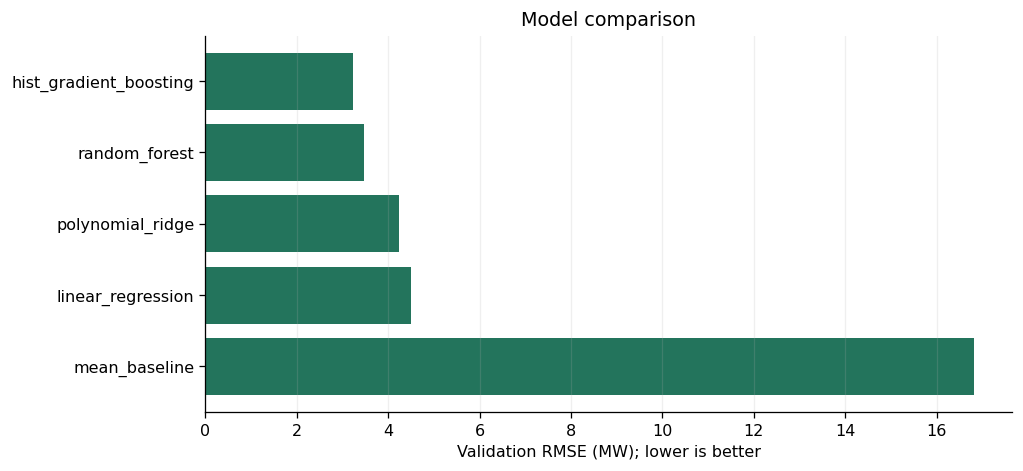

In [7]:
comparison = pd.DataFrame(results['models'])
display(comparison[['model', 'cv_rmse_mw', 'cv_std_mw', 'validation_rmse_mw', 'validation_mae_mw', 'validation_r2']])
display(pd.DataFrame(results['tuning_trials']).sort_values(['model', 'cv_rmse_mw']).reset_index(drop=True))
print('Selected model:', results['selected_model'])
print('Best parameters:', comparison.iloc[0]['best_parameters'])

plot = comparison.sort_values('validation_rmse_mw', ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(plot['model'], plot['validation_rmse_mw'], color='#23745c')
ax.set(xlabel='Validation RMSE (MW); lower is better', title='Model comparison')
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
fig.savefig(REPORTS / 'model_comparison.png', dpi=150)
plt.show()

## 4. Feature importance

Permutation importance measures the increase in validation RMSE after shuffling
one input, repeated ten times. It is calculated using the selected model trained
on the training partition, before final refitting.

Larger increases indicate more useful predictive information. Correlated
features can mask one another, and this analysis is not causal attribution.

,feature,rmse_increase_mw,std_mw
0,AT,16.246093,0.331956
1,V,3.307267,0.073683
2,AP,0.859036,0.020048
3,RH,0.765514,0.032529


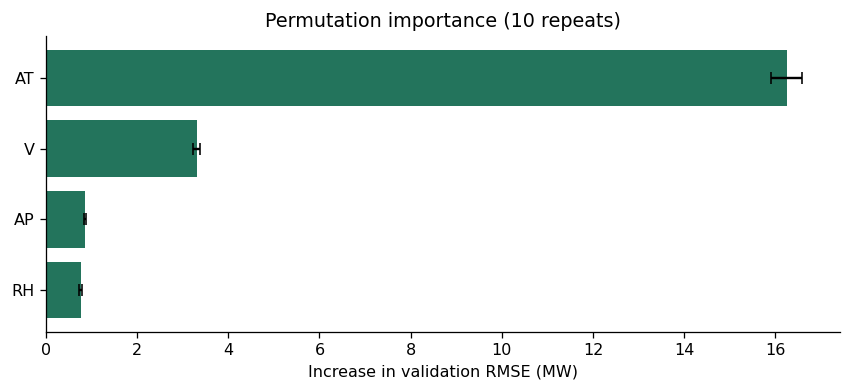

In [8]:
importance = pd.DataFrame(results['permutation_importance_on_validation'])
display(importance)
plot = importance.sort_values('rmse_increase_mw')
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.barh(plot['feature'], plot['rmse_increase_mw'], xerr=plot['std_mw'], color='#23745c', capsize=4)
ax.set(xlabel='Increase in validation RMSE (MW)', title='Permutation importance (10 repeats)')
fig.tight_layout()
fig.savefig(REPORTS / 'permutation_importance.png', dpi=150)
plt.show()

## 5. Held-out evaluation and error analysis

Only the selected configuration is refitted and scored on test. A mean-output
dummy is also evaluated as a benchmark. A paired bootstrap of the held-out
observations provides an approximate 95% interval for RMSE. It does not account
for unobserved temporal dependence or deployment to another plant.

The residual plot and largest-error table reveal a small tail of large errors,
including errors above 20 MW. A low aggregate RMSE does not guarantee every
estimate is close. These cases require investigation before operational use;
we do not remove them after inspecting test performance.


,rmse_mw,mae_mw,r2
mean baseline,17.143337,14.973022,-2.467395e-07
hist_gradient_boosting,3.262464,2.269396,9.637840e-01


Approximate test RMSE bootstrap interval: [2.934231576802057, 3.6618695112681987]


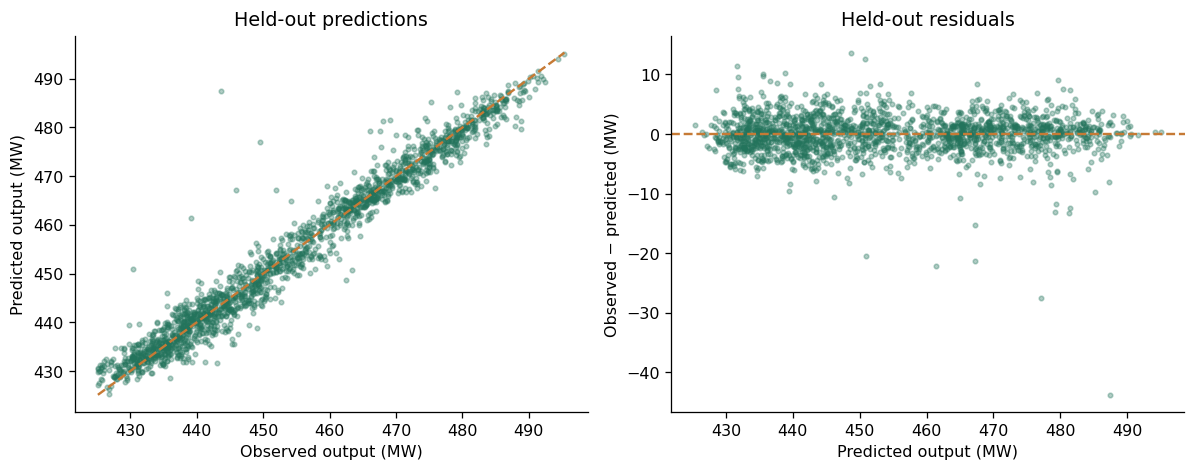

,AT,V,AP,RH,PE,prediction_mw,residual_mw
1026,6.22,39.85,1012.05,86.88,443.73,487.481111,-43.751111
700,11.41,41.40,1019.01,78.59,449.50,477.049123,-27.549123
1781,15.61,38.52,1018.40,80.99,439.21,461.375844,-22.165844
220,13.78,40.10,1014.49,81.86,445.98,467.224400,-21.244400
637,18.60,58.71,1009.80,86.42,430.38,450.890437,-20.510437
154,13.32,41.70,1020.22,88.30,451.93,467.248033,-15.318033
706,21.12,47.24,1003.79,70.55,462.41,448.764926,13.645074
495,9.57,39.82,1013.12,89.15,468.02,481.281102,-13.261102
434,7.33,41.16,1023.17,92.43,466.16,479.258021,-13.098021
1537,23.74,49.50,1013.20,49.51,463.40,450.833790,12.566210


In [9]:
display(pd.DataFrame([results['test_mean_baseline'], results['test_metrics']], index=['mean baseline', results['selected_model']]))
print('Approximate test RMSE bootstrap interval:', results['test_rmse_bootstrap_95pct'])
errors = pd.read_csv(REPORTS / 'test_predictions.csv')
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].scatter(errors[TARGET], errors['prediction_mw'], s=8, alpha=.35, color='#23745c')
lo, hi = min(errors[TARGET].min(), errors['prediction_mw'].min()), max(errors[TARGET].max(), errors['prediction_mw'].max())
axes[0].plot([lo, hi], [lo, hi], '--', color='#c67a35')
axes[0].set(xlabel='Observed output (MW)', ylabel='Predicted output (MW)', title='Held-out predictions')
axes[1].scatter(errors['prediction_mw'], errors['residual_mw'], s=8, alpha=.35, color='#23745c')
axes[1].axhline(0, linestyle='--', color='#c67a35')
axes[1].set(xlabel='Predicted output (MW)', ylabel='Observed − predicted (MW)', title='Held-out residuals')
fig.tight_layout()
fig.savefig(REPORTS / 'test_diagnostics.png', dpi=150)
plt.show()
display(errors.reindex(errors['residual_mw'].abs().sort_values(ascending=False).index).head(10))

## 6. Saved model and deployment

The persisted artifact is a complete sklearn pipeline; preprocessing is not
reimplemented independently in the API. `predict.py` checks the artifact hash
and sklearn version on startup. It exposes `GET /health`, `POST /predict`,
interactive API documentation at `/docs`, and a small browser demo at `/`.

Request validation rejects missing fields, unknown fields, non-finite values,
and clearly invalid inputs. Broader physical validation bounds are separate
from observed training ranges; extrapolation within the broad bounds is flagged.

In [10]:
model = joblib.load(ROOT / 'models/model.joblib')
example = pd.DataFrame([{'AT': 19.0, 'V': 54.0, 'AP': 1013.0, 'RH': 73.0}], columns=FEATURES)
print('Example same-hour output estimate:', round(float(model.predict(example)[0]), 3), 'MW')
display(pd.Series(json.loads((ROOT / 'models/metadata.json').read_text())))

Example same-hour output estimate: 454.878 MW


model_name                                    hist_gradient_boosting
features                                             [AT, V, AP, RH]
target                                                            PE
output_unit                                                       MW
python                                                       3.11.15
scikit_learn                                                   1.7.2
numpy                                                          2.3.3
pandas                                                         2.3.2
model_sha256       d676a5a6cba59c3da25cda811c3b0cd87d42ee4e450ee9...
data_csv_sha256    51848da3c8b8c29f709f159fad95443eaa8ff2e95c721a...
training_rows                                                   7621
evaluation         {'rmse_mw': 3.262464204188433, 'mae_mw': 2.269...
training_ranges    {'AT': {'min': 1.81, 'max': 37.11}, 'V': {'min...
best_parameters    {'model__l2_regularization': 0.0, 'model__lear...
dtype: object

Run the API in a terminal:

```bash
uv run uvicorn predict:app --host 0.0.0.0 --port 9696
```

Then open `http://localhost:9696` or, in another terminal, run:

```bash
uv run python smoke_test.py
```

Docker:

```bash
docker build -t power-output:midterm .
docker run --rm -p 9696:9696 power-output:midterm
```

The README distinguishes actual local HTTP verification from the Docker/cloud
steps that still require a Docker-capable host/account. A rendered record of actual local HTTP requests is in
`reports/http-verification.png`; it is not a browser screenshot. Capture a
browser screenshot after verifying Docker on your computer.

## Limitations and next steps

- Data come from one plant operating at full load; the model is not validated for
  partial load or different equipment.
- Measurements are historical and lack usable timestamps. Randomly held-out
  performance is not evidence of future-time forecasting quality.
- Exhaust vacuum is an operating measurement and must be available when making
  an estimate. This is not a weather-only forecasting model.
- No calibrated per-prediction interval or plant-control recommendation is provided.
- An operational system would need dated data, a temporal backtest, monitoring,
  and validation with domain experts.

## Attribution and AI assistance

Dataset: Tufekci, P. and Kaya, H. (2014), UCI Machine Learning Repository,
DOI 10.24432/C5002N, CC BY 4.0. Sheet1 was converted to CSV and duplicates were removed.
AI assistance was used to draft implementation, documentation, and explanations.
Computed scores and verification evidence are generated by executable code;
the author should review and be able to explain the submitted solution.